In [1]:
import os, shutil
import zipfile
import random
from random import sample
import shutil
from shutil import copyfile
import pathlib
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm as tq

In [2]:
import cv2
from PIL import Image
import skimage
from skimage import io
from skimage.transform import resize
from skimage.transform import rotate, AffineTransform, warp
from skimage import img_as_ubyte
from skimage.exposure import adjust_gamma
from skimage.util import random_noise

In [3]:
import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import Model, layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.layers import InputLayer, Conv2D, SeparableConv2D, MaxPooling2D, MaxPool2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom, RandomFlip
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.densenet import DenseNet121
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, Callback, EarlyStopping, ReduceLROnPlateau

In [4]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [5]:
# Setingan Manual Model
IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 123
RANDOM_STATE = 42

In [6]:
from google.colab import files
files.view("/content/drive/MyDrive/DEEP LEARNING/kaggle.json")

<IPython.core.display.Javascript object>

In [7]:
!kaggle datasets download -d muhammadmasdar/tomato-disease-ready
!unzip tomato-disease-ready.zip

Streaming output truncated to the last 5000 lines.
  inflating: tomato_disease_ready/train/late_blight/e10eb7f2-7449-4061-bb0a-49fa55abd423___RS_Late.B 6718.JPG  
  inflating: tomato_disease_ready/train/late_blight/e114b022-a00f-4055-9ff0-ae67c6722607___RS_Late.B 5024.JPG  
  inflating: tomato_disease_ready/train/late_blight/e131a4c1-21d7-40cd-a19f-02456e411750___GHLB Leaf 3 Day 1.JPG  
  inflating: tomato_disease_ready/train/late_blight/e142d2de-6aeb-4d1c-9184-d6e46647ad6a___RS_Late.B 5203.JPG  
  inflating: tomato_disease_ready/train/late_blight/e14dc5d0-5671-43e0-9d32-a8331c9455a4___RS_Late.B 6123.JPG  
  inflating: tomato_disease_ready/train/late_blight/e1501757-3235-4051-b460-52c0f6e45add___RS_Late.B 4910.JPG  
  inflating: tomato_disease_ready/train/late_blight/e1836b6b-a14d-402a-ac9f-db7d12feeec9___RS_Late.B 4924.JPG  
  inflating: tomato_disease_ready/train/late_blight/e19d885a-349c-4e13-b015-5c17d2895b30___GHLB2 Leaf 94.JPG  
  inflating: tomato_disease_ready/train/late_blight

In [8]:
disease = os.listdir("/content/tomato_disease_ready/train")
fileName = "tomato_disease"

os.makedirs(fileName)
for ds in disease :
  shutil.move(f"/content/tomato_disease_ready/train/{ds}", os.path.join(fileName, ds))

In [9]:
test_fol = "/content/tomato_disease_ready/test"
val_fol = "/content/tomato_disease_ready/validation"

for tsf in os.listdir(test_fol) :
  for i in os.listdir(os.path.join(test_fol, tsf)):
    print(os.path.join(test_fol, tsf, i))
    shutil.move(os.path.join(test_fol, tsf, i), os.path.join(fileName, tsf))

for vlf in os.listdir(val_fol) :
  for i in os.listdir(os.path.join(val_fol, vlf)):
    print(os.path.join(val_fol, vlf, i))
    shutil.move(os.path.join(val_fol, vlf, i), os.path.join(fileName, vlf))

/content/tomato_disease_ready/test/healthy/5418b9ca-804d-4219-8272-805c0d78c28b___GH_HL Leaf 404.1.JPG
/content/tomato_disease_ready/test/healthy/3887cbce-afde-4244-b39e-25ee0c9e24fc___GH_HL Leaf 235.1.JPG
/content/tomato_disease_ready/test/healthy/5630c5b1-a956-4a34-879a-eb1cb89d22d1___RS_HL 9806.JPG
/content/tomato_disease_ready/test/healthy/6555b55c-78bc-4391-88ed-65b596fc7e76___GH_HL Leaf 441.JPG
/content/tomato_disease_ready/test/healthy/3181ca61-aaa0-4263-a141-2760d164f84b___GH_HL Leaf 189.1.JPG
/content/tomato_disease_ready/test/healthy/5393abd2-b4e2-4af2-94d4-c52c919fc157___RS_HL 0322.JPG
/content/tomato_disease_ready/test/healthy/6550c4ca-9494-4de5-8909-d0cdab8f0892___RS_HL 0401.JPG
/content/tomato_disease_ready/test/healthy/3247a6d7-a473-414f-af51-2d8de917ee82___RS_HL 9622.JPG
/content/tomato_disease_ready/test/healthy/6949b108-03f0-4cee-b91a-bb5b23e93249___GH_HL Leaf 331.3.JPG
/content/tomato_disease_ready/test/healthy/3796ec31-0263-4e17-a312-7871e7b5c0c2___GH_HL Leaf 486.JP

In [10]:
shutil.rmtree("/content/tomato_disease_ready")

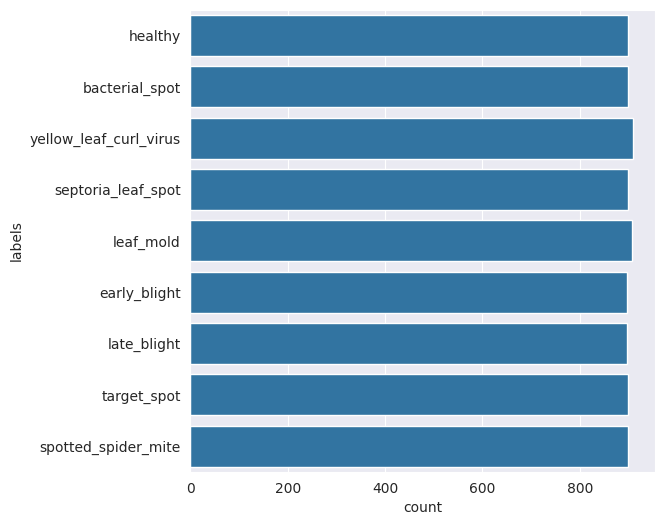

In [11]:
lung_path = fileName

file_name = []
labels = []
full_path = []

for path, subdirs, files in os.walk(lung_path):
    for name in files:
        full_path.append(os.path.join(path, name))
        labels.append(path.split('/')[-1])
        file_name.append(name)

distribution_image = pd.DataFrame({"path":full_path, 'file_name':file_name, "labels":labels})

Label = distribution_image['labels']
plt.figure(figsize = (6,6))
sns.set_style("darkgrid")
plot_data = sns.countplot(Label)

In [12]:
for distribusion in distribution_image['labels'].unique():
  print(f"Total {distribusion} : {distribution_image[distribution_image['labels'] == distribusion].count()['labels']}")

print("===================================================")
print(f"Total Dataset Image Keseluruhan : {Label.count()}")

Total healthy : 900
Total bacterial_spot : 899
Total yellow_leaf_curl_virus : 910
Total septoria_leaf_spot : 899
Total leaf_mold : 908
Total early_blight : 897
Total late_blight : 898
Total target_spot : 900
Total spotted_spider_mite : 900
Total Dataset Image Keseluruhan : 8111


In [13]:
df = distribution_image.copy()
df.head()

,path,file_name,labels
0,tomato_disease/healthy/95973ed9-f9a8-4c71-b232...,95973ed9-f9a8-4c71-b232-432f61020fe3___GH_HL L...,healthy
1,tomato_disease/healthy/dc3a13dc-a628-433f-a038...,dc3a13dc-a628-433f-a038-a3f377bc608e___GH_HL L...,healthy
2,tomato_disease/healthy/2969446c-455d-4ad3-a0f4...,2969446c-455d-4ad3-a0f4-25786dca0841___RS_HL 9...,healthy
3,tomato_disease/healthy/0902aa8e-e4f7-4c29-b11a...,0902aa8e-e4f7-4c29-b11a-b2b7f24fe61c___GH_HL L...,healthy
4,tomato_disease/healthy/a8070204-763a-47f2-9b83...,a8070204-763a-47f2-9b83-445c17975cdf___RS_HL 0...,healthy


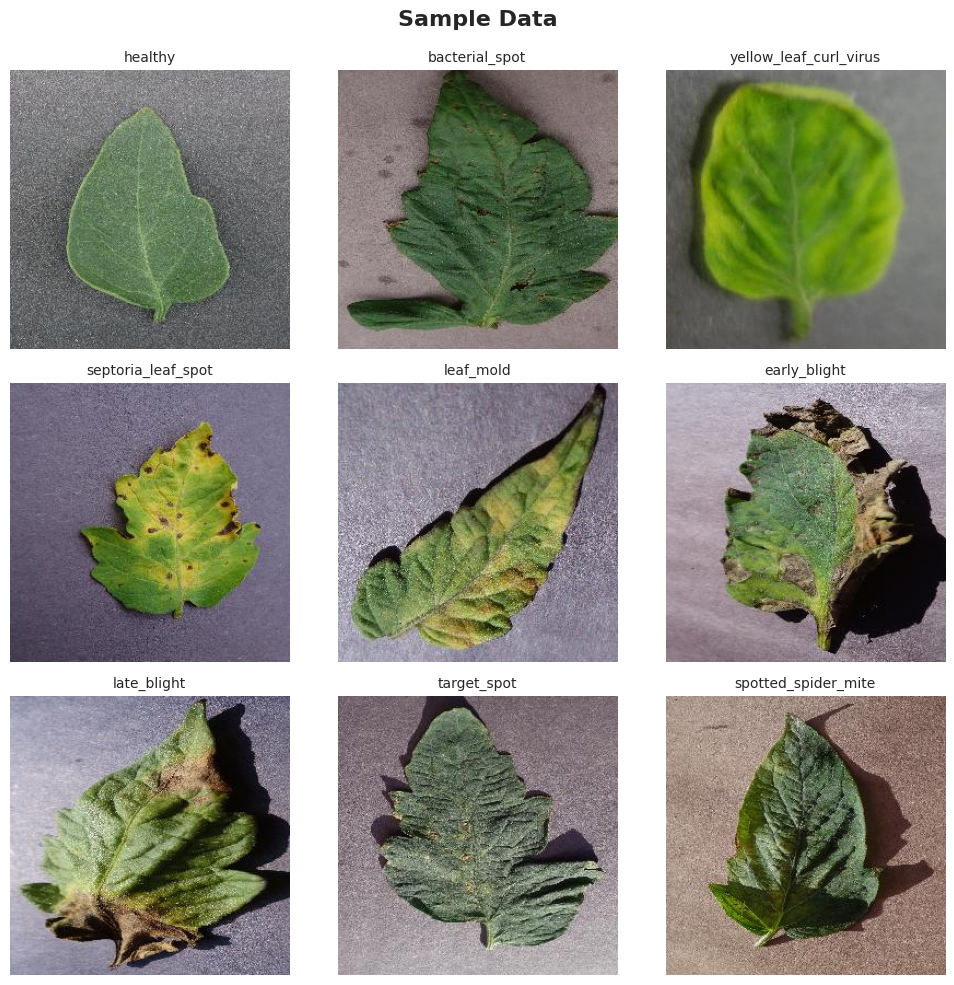

In [14]:
unique_labels = df['labels'].unique()

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Sample Data", fontsize=16, fontweight='bold')

axes = axes.flatten()

for i, uniq in enumerate(unique_labels):
    sample_path = df[df['labels'] == uniq]['path'].values[0]

    img = Image.open(sample_path)

    axes[i].imshow(img)
    axes[i].set_title(uniq, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [15]:
X= df['path']
y= df['labels']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True, stratify=y)

In [16]:
df_tr = pd.DataFrame({'path':X_train,'labels':y_train,'set':'train'})
df_te = pd.DataFrame({'path':X_test,'labels':y_test,'set':'test'})
df_all = pd.concat([df_tr, df_te], ignore_index=True)

print('===================================================== \n')
print(df_all.groupby(['set', 'labels']).size(), '\n')
print('===================================================== \n')

print(df_all.sample(5))


set    labels                
test   bacterial_spot            180
       early_blight              179
       healthy                   180
       late_blight               180
       leaf_mold                 182
       septoria_leaf_spot        180
       spotted_spider_mite       180
       target_spot               180
       yellow_leaf_curl_virus    182
train  bacterial_spot            719
       early_blight              718
       healthy                   720
       late_blight               718
       leaf_mold                 726
       septoria_leaf_spot        719
       spotted_spider_mite       720
       target_spot               720
       yellow_leaf_curl_virus    728
dtype: int64 


                                                   path          labels    set
7946  tomato_disease/bacterial_spot/ad7c1b29-cdb8-41...  bacterial_spot   test
2186  tomato_disease/target_spot/92d6e053-7bed-4d98-...     target_spot  train
5005  tomato_disease/leaf_mold/e7ebe82b-5573-47ff-

In [17]:
df_all.head()

,path,labels,set
0,tomato_disease/leaf_mold/74cb417c-24ca-43b2-89...,leaf_mold,train
1,tomato_disease/early_blight/32065728-b0b0-4840...,early_blight,train
2,tomato_disease/target_spot/a4b219dd-fcf0-4c1f-...,target_spot,train
3,tomato_disease/early_blight/6873f362-d13b-41f7...,early_blight,train
4,tomato_disease/bacterial_spot/c8875e15-728e-4c...,bacterial_spot,train


In [18]:
datasource_path = lung_path
dataset_path = "new_dataset/"

for index, row in tq(df_all.iterrows()):
    file_path = row['path']
    if os.path.exists(file_path) == False:
            file_path = os.path.join(datasource_path,row['labels'],row['image'].split('.')[0])

    if os.path.exists(os.path.join(dataset_path,row['set'],row['labels'])) == False:
        os.makedirs(os.path.join(dataset_path,row['set'],row['labels']))

    destination_file_name = file_path.split('/')[-1]
    file_dest = os.path.join(dataset_path,row['set'],row['labels'],destination_file_name)

    if os.path.exists(file_dest) == False:
        shutil.copy2(file_path,file_dest)

0it [00:00, ?it/s]

In [19]:
TRAIN_DIR = "new_dataset/train/"
TEST_DIR = "new_dataset/test/"
arr_train = []
arr_test = []

for key, data in enumerate(os.listdir(TRAIN_DIR)):
  dict_train = {"train_name" : f"train_{data}",
                "train_path" : os.path.join(f"{TRAIN_DIR}{data}")}
  arr_train.append(dict_train)
for key, data in enumerate(os.listdir(TEST_DIR)):
  dict_test = {"test_name" : f"test_{data}",
                "test_path" : os.path.join(f"{TEST_DIR}{data}")}
  arr_test.append(dict_test)

for ar_tr in arr_train:
  print(f"Total number of {ar_tr["train_name"].replace("_", " ")} : {len(os.listdir(ar_tr["train_path"]))}")

print("===================================================")

for ar_ts in arr_test:
  print(f"Total number of {ar_ts["test_name"].replace("_", " ")} : {len(os.listdir(ar_ts["test_path"]))}")

Total number of train healthy : 720
Total number of train bacterial spot : 719
Total number of train yellow leaf curl virus : 728
Total number of train septoria leaf spot : 719
Total number of train leaf mold : 726
Total number of train early blight : 718
Total number of train late blight : 718
Total number of train target spot : 720
Total number of train spotted spider mite : 720
Total number of test healthy : 180
Total number of test bacterial spot : 180
Total number of test yellow leaf curl virus : 182
Total number of test septoria leaf spot : 180
Total number of test leaf mold : 182
Total number of test early blight : 179
Total number of test late blight : 180
Total number of test target spot : 180
Total number of test spotted spider mite : 180


In [30]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical'
)
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
class_names = test_dataset.class_names
NUM_CLASSES = len(train_dataset.class_names)
print(f"Jumlah kelas terdeteksi: {NUM_CLASSES}")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Found 6488 files belonging to 9 classes.
Using 5191 files for training.
Found 6488 files belonging to 9 classes.
Using 1297 files for validation.
Found 1623 files belonging to 9 classes.
Jumlah kelas terdeteksi: 9


In [31]:
data_augmentation = Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomTranslation(height_factor=0.2, width_factor=0.2),
    RandomZoom(0.2),
], name="augmentation_layer")

# LAYER BARU KHUSUS MOBILENETV2 (Rumus: (x / 127.5) - 1 )
# Ini mengubah rentang 0-255 menjadi -1 sampai 1
mobilenet_preprocess = Rescaling(scale=1./127.5, offset=-1, name="mobilenet_rescale")

# Muat Base Model MobileNetV2
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Rangkai Model
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = mobilenet_preprocess(x)         # <--- Masukkan layer rescale di sini!
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs, outputs)

In [32]:
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
    ModelCheckpoint(filepath='model_tomat_mobilenetv2.keras', monitor='val_accuracy', save_best_only=True)
]

In [33]:
print("\n--- MULAI TAHAP 1: FEATURE EXTRACTION ---")
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])

history_1 = model.fit(train_dataset, validation_data=val_dataset, epochs=15, callbacks=callbacks_list)


--- MULAI TAHAP 1: FEATURE EXTRACTION ---
Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 25s 91ms/step - accuracy: 0.4789 - loss: 1.4627 - val_accuracy: 0.6962 - val_loss: 0.9599 - learning_rate: 0.0010
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - accuracy: 0.6791 - loss: 0.9335 - val_accuracy: 0.7294 - val_loss: 0.7959 - learning_rate: 0.0010
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.7178 - loss: 0.8216 - val_accuracy: 0.7556 - val_loss: 0.7141 - learning_rate: 0.0010
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.7417 - loss: 0.7510 - val_accuracy: 0.7718 - val_loss: 0.6687 - learning_rate: 0.0010
Epoch 5/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.7501 - loss: 0.7152 - val_accuracy: 0.7810 - val_loss: 0.6305 - learning_rate: 0.0010
Epoch 6/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 66ms/step - accuracy: 0.7642 - loss: 0.6807 - val_accuracy: 0.7903 - val_loss: 0.6214 - learning_rate: 0.0010
Epoch 7/15
163/163 ━━━━━━━━━━━━━━

In [34]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.8312 - loss: 0.5081
--------------------------------------------------
TEST ACCURACY: 0.8312 (83.12%)
TEST LOSS:     0.5081
--------------------------------------------------


In [35]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step

CLASSIFICATION REPORT:
                        precision    recall  f1-score   support

        bacterial_spot       0.75      0.88      0.81       180
          early_blight       0.83      0.63      0.72       179
               healthy       0.90      0.95      0.92       180
           late_blight       0.87      0.81      0.84       180
             leaf_mold       0.86      0.84      0.85       182
    septoria_leaf_spot       0.81      0.74      0.78       180
   spotted_spider_mite       0.87      0.79      0.83       180
           target_spot       0.66      0.89      0.76       180
yellow_leaf_curl_virus       0.99      0.95      0.97       182

              accuracy                           0.83      1623
             macro avg       0.84      0.83      0.83      1623
          weighted avg       0.84      0.83      0.83      1623



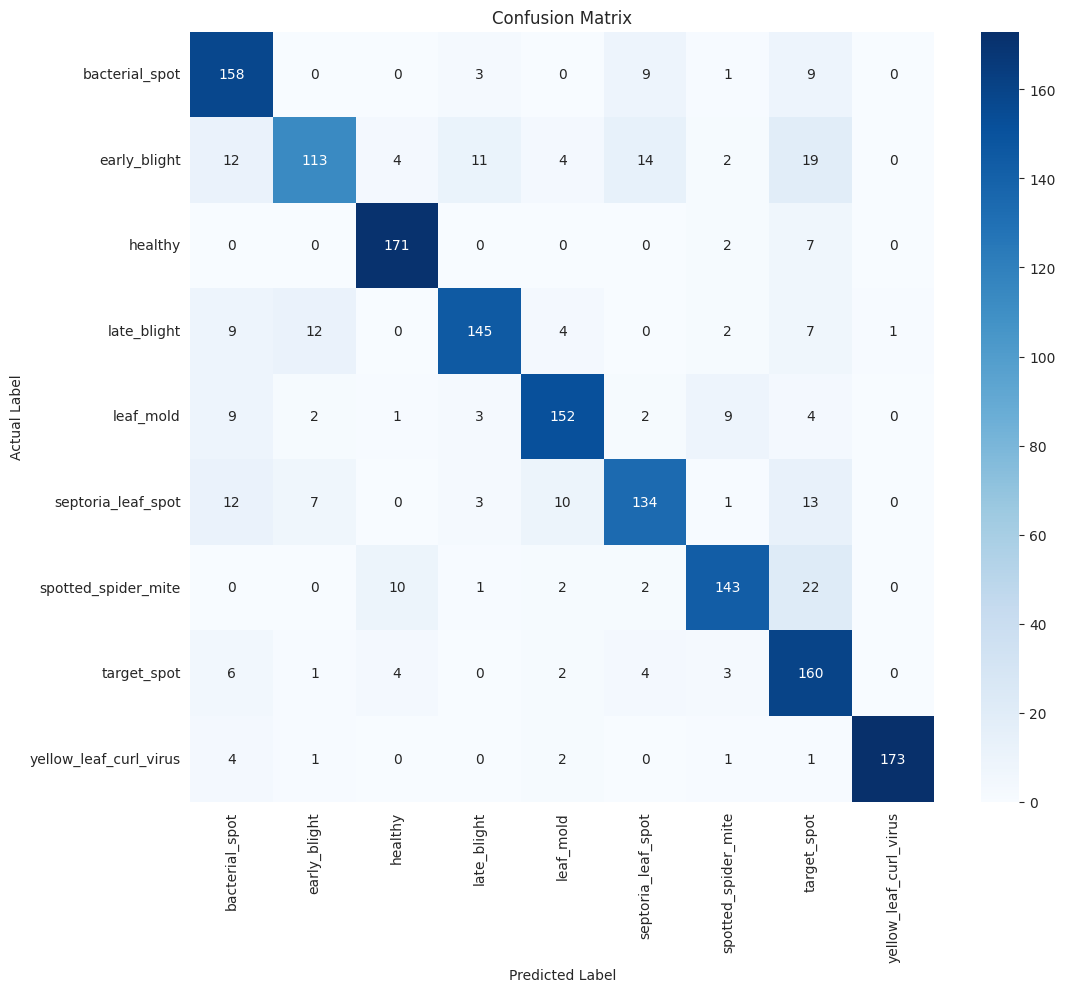

In [36]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

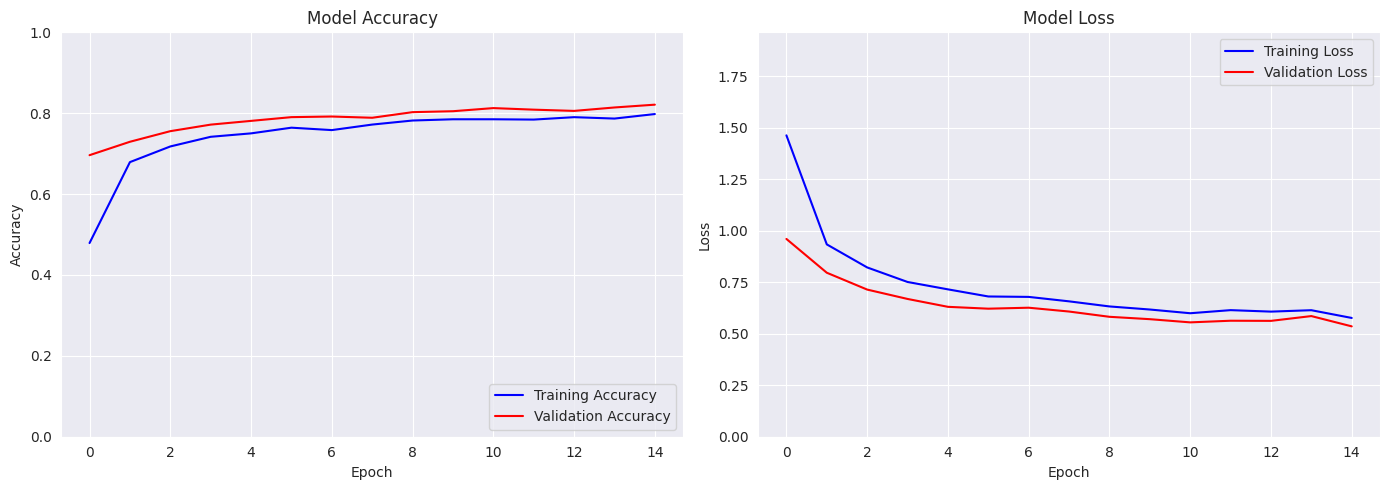

In [37]:
if 'history_1' in locals():
    acc = history_1.history['accuracy']
    val_acc = history_1.history['val_accuracy']
    loss = history_1.history['loss']
    val_loss = history_1.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [38]:
shutil.copy("/content/model_tomat_mobilenetv2.keras", "/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/Model/MobileNetV2_pre-trained.keras")

'/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/Model/MobileNetV2_pre-trained.keras'

In [39]:
def predict_image(img_path, model, class_names):
    # 1. Muat gambar dan pastikan ukurannya sesuai dengan input model
    img = image.load_img(img_path, target_size=(224, 224))

    # 2. Ubah gambar menjadi array
    img_array = image.img_to_array(img)

    # 3. Tambahkan dimensi batch (dari (224, 224, 3) menjadi (1, 224, 224, 3))
    img_array = np.expand_dims(img_array, axis=0)

    # CATATAN: Rescale (img_array /= 255.0) sengaja ditiadakan untuk EfficientNet

    # 4. Lakukan prediksi
    predictions = model.predict(img_array)

    # 5. Ekstrak hasil
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0])

    print(f'Predicted: {class_names[predicted_class]} (Confidence: {confidence:.2%})')

    # Opsional: Kembalikan nilai jika ingin digunakan di variabel lain
    return class_names[predicted_class], confidence

predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel1.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel2.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel3.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel4.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel5.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel6.jpeg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted: leaf_mold (Confidence: 99.16%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted: late_blight (Confidence: 39.95%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Predicted: leaf_mold (Confidence: 95.64%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted: bacterial_spot (Confidence: 40.16%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Predicted: leaf_mold (Confidence: 52.03%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted: bacterial_spot (Confidence: 98.80%)


('bacterial_spot', np.float32(0.98802465))

In [40]:
print("\n--- MULAI TAHAP 2: FINE TUNING ---")
base_model.trainable = True

# Biarkan Batch Normalization membeku
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # LR SANGAT KECIL
              loss='categorical_crossentropy', metrics=['accuracy'])

history_2 = model.fit(train_dataset, validation_data=val_dataset, epochs=20, callbacks=callbacks_list)


--- MULAI TAHAP 2: FINE TUNING ---
Epoch 1/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 149ms/step - accuracy: 0.8193 - loss: 0.5117 - val_accuracy: 0.8527 - val_loss: 0.4257 - learning_rate: 1.0000e-05
Epoch 2/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 21s 132ms/step - accuracy: 0.8544 - loss: 0.4198 - val_accuracy: 0.8296 - val_loss: 0.4752 - learning_rate: 1.0000e-05
Epoch 3/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 22s 133ms/step - accuracy: 0.8761 - loss: 0.3623 - val_accuracy: 0.8419 - val_loss: 0.4320 - learning_rate: 1.0000e-05
Epoch 4/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - accuracy: 0.8835 - loss: 0.3339 - val_accuracy: 0.8897 - val_loss: 0.3028 - learning_rate: 1.0000e-05
Epoch 5/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 22s 136ms/step - accuracy: 0.8914 - loss: 0.3090 - val_accuracy: 0.8520 - val_loss: 0.4366 - learning_rate: 1.0000e-05
Epoch 6/20
163/163 ━━━━━━━━━━━━━━━━━━━━ 22s 135ms/step - accuracy: 0.9044 - loss: 0.2766 - val_accuracy: 0.8635 - val_loss: 0.3890 - learning_rate: 1.0000e-05
Epoch 7/20

In [41]:
print("Sedang mengevaluasi model pada Data Test...")
test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"--------------------------------------------------")
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"TEST LOSS:     {test_loss:.4f}")
print(f"--------------------------------------------------")

Sedang mengevaluasi model pada Data Test...
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9119 - loss: 0.2802
--------------------------------------------------
TEST ACCURACY: 0.9119 (91.19%)
TEST LOSS:     0.2802
--------------------------------------------------


In [42]:
print("Melakukan prediksi...")
# 1. Prediksi langsung dengan memanggil dataset (tidak perlu reset atau steps)
predictions = model.predict(test_dataset)

# 2. Ubah probabilitas menjadi index kelas tertinggi
predicted_classes = np.argmax(predictions, axis=1)

# 3. Ekstrak label asli (true labels) langsung dari test_dataset
# Karena kita menggunakan label_mode='categorical', label berbentuk one-hot (misal: [0, 1, 0])
true_labels_onehot = np.concatenate([y for x, y in test_dataset], axis=0)
true_classes = np.argmax(true_labels_onehot, axis=1)

# 4. Ambil nama kelas (menggunakan variabel class_names yang sudah kita definisikan saat training)
# Jika variabel class_names hilang di cell/notebook, Anda bisa memanggilnya lagi lewat test_dataset aslinya
# class_names = ['healthy', 'bacterial_spot', ...]

print("\nCLASSIFICATION REPORT:")
print(classification_report(true_classes, predicted_classes, target_names=class_names))

Melakukan prediksi...
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step

CLASSIFICATION REPORT:
                        precision    recall  f1-score   support

        bacterial_spot       0.89      0.93      0.91       180
          early_blight       0.93      0.77      0.84       179
               healthy       0.97      0.99      0.98       180
           late_blight       0.90      0.92      0.91       180
             leaf_mold       0.92      0.97      0.94       182
    septoria_leaf_spot       0.92      0.81      0.86       180
   spotted_spider_mite       0.95      0.91      0.93       180
           target_spot       0.76      0.93      0.84       180
yellow_leaf_curl_virus       1.00      0.97      0.98       182

              accuracy                           0.91      1623
             macro avg       0.92      0.91      0.91      1623
          weighted avg       0.92      0.91      0.91      1623



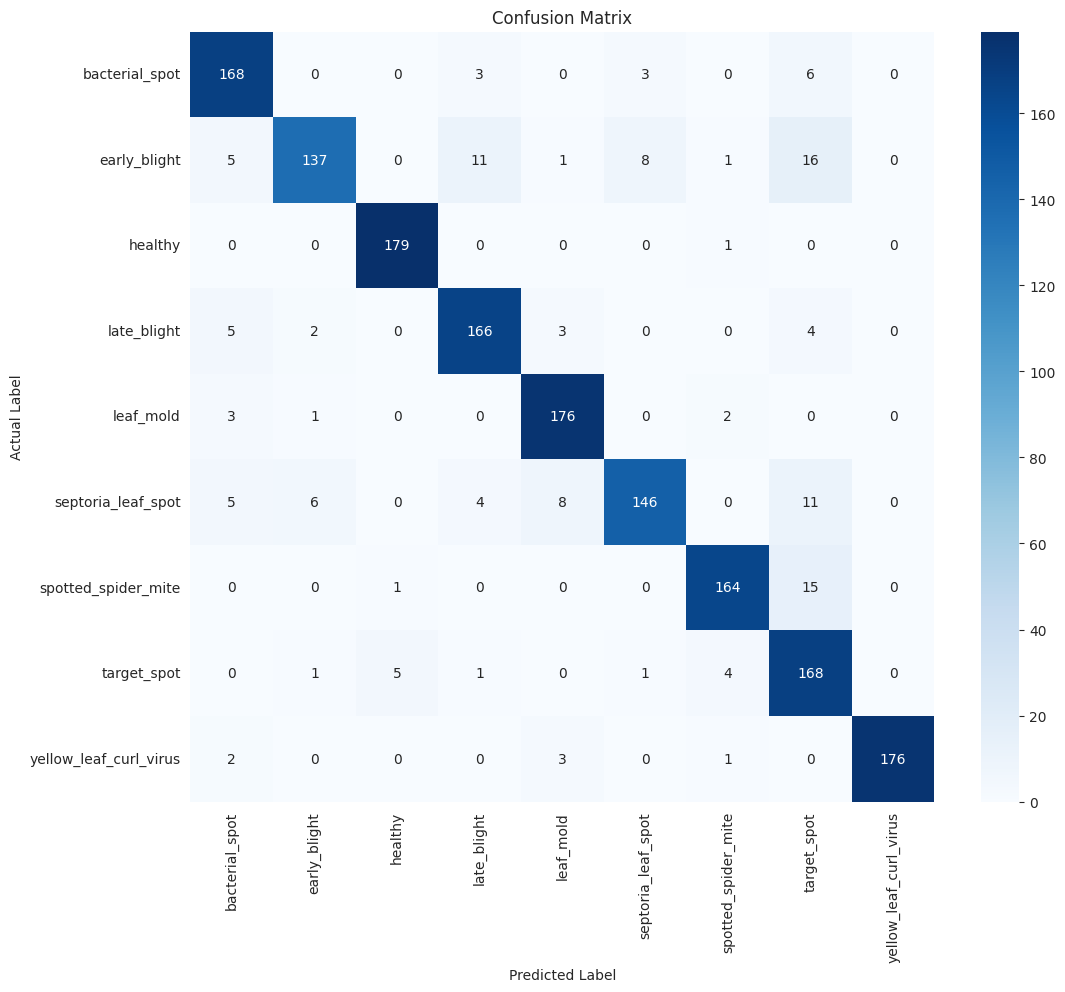

In [43]:
cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

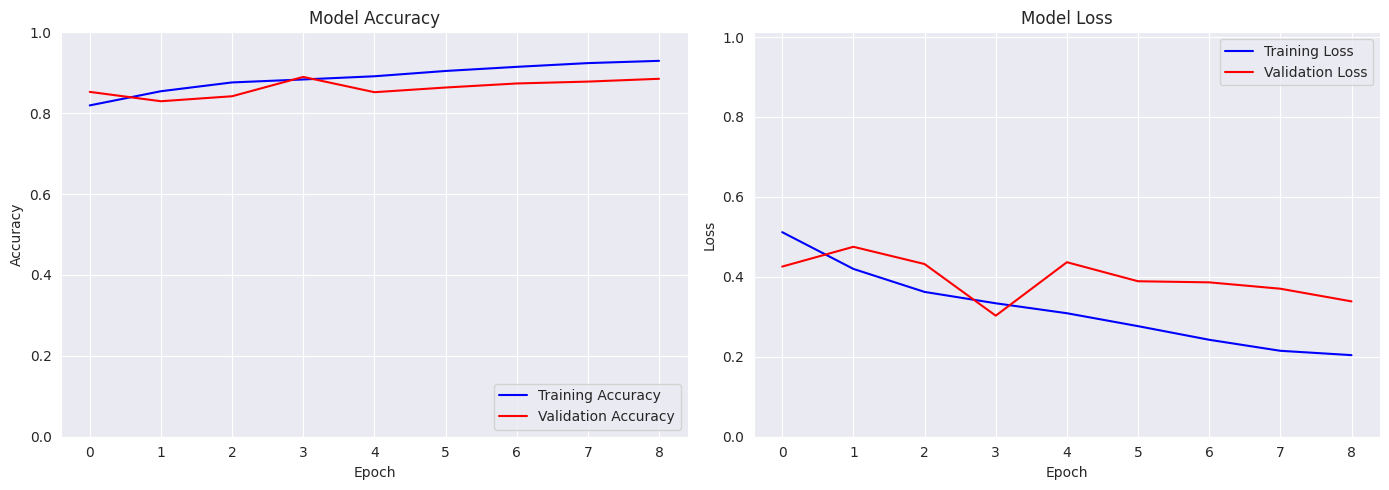

In [44]:
if 'history_2' in locals():
    acc = history_2.history['accuracy']
    val_acc = history_2.history['val_accuracy']
    loss = history_2.history['loss']
    val_loss = history_2.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.ylim([0, 1])

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, 'b-', label='Training Loss')
    plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.ylim([0, max(loss)+0.5])

    plt.tight_layout()
    plt.show()
else:
    print("Variabel 'history' tidak ditemukan. Pastikan Anda menyimpan output model.fit ke variabel 'history'.")

In [45]:
shutil.copy("/content/model_tomat_mobilenetv2.keras", "/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/Model/MobileNetV2_fine-tuning.keras")

'/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/Model/MobileNetV2_fine-tuning.keras'

In [46]:
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel1.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel2.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel3.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel4.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel5.jpeg', model, class_names)
predict_image('/content/drive/MyDrive/DEEP LEARNING/Tomato Disease/sample/sampel6.jpeg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted: leaf_mold (Confidence: 99.82%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Predicted: bacterial_spot (Confidence: 93.49%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Predicted: leaf_mold (Confidence: 99.04%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Predicted: late_blight (Confidence: 42.43%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted: leaf_mold (Confidence: 92.76%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Predicted: bacterial_spot (Confidence: 99.75%)


('bacterial_spot', np.float32(0.99751055))

In [47]:
predict_image('/content/FetkYJQL4n7taBqjiHSiQ9.jpg', model, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
Predicted: septoria_leaf_spot (Confidence: 99.12%)


('septoria_leaf_spot', np.float32(0.99119395))